# 09 – Final evaluation on the test set

The selected model (notebook 07) is trained once on the full training set and applied to the test set with the threshold and cost assumptions fixed in notebook 08. The test set is used here for the first and only time; nothing is changed based on these results.

Uncertainty is reported as 95% intervals: a bootstrap over the test jobs (2,000 resamples) for the overall metrics, and Wilson intervals for the per-mode recalls, which rest on small counts.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

from config import (COST_FAILURE, COST_INTERVENTION, CURRENCY, FIG_DIR, H1_MIN_PRECISION, H1_MIN_RECALL,
                    H2_MIN_FOLDS, H2_MIN_GAIN, H3_MIN_GAIN, H4_MAX_RECALL_TWF, H4_MIN_RECALL_RULE_MODES,
                    H5_TOOL_WEAR_RULE, RESULTS_DIR, SEED)
from data import load_train_test
from features import build_features
from models import make_pipeline

train, test = load_train_test()
X_train, y_train = build_features(train)
X_test, y_test = build_features(test)

with open(RESULTS_DIR / "07_selected_model.json") as f:
    selection = json.load(f)
with open(RESULTS_DIR / "08_threshold.json") as f:
    decision = json.load(f)
threshold = decision["threshold"]
print(f"Model: {selection['model']} ({selection['features']} features), params {selection['params']}")
print(f"Threshold: {threshold}; costs: intervention {COST_INTERVENTION:,}, breakdown {COST_FAILURE:,} {CURRENCY}")
print(f"Test set: {len(test)} jobs, {int(y_test.sum())} failures")

Model: random_forest (physics features), params {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 5}
Threshold: 0.24; costs: intervention 1,000, breakdown 10,000 CAD
Test set: 2992 jobs, 99 failures


## 1. Train the final model and predict the test set

In [2]:
model = make_pipeline(selection["model"], selection["features"], **selection["params"])
model.fit(X_train, y_train)

probability = model.predict_proba(X_test)[:, 1]
alarm = probability >= threshold
pd.DataFrame({"UDI": test["UDI"], "failure": y_test, "probability": probability, "alarm": alarm}).to_csv(
    RESULTS_DIR / "09_test_predictions.csv", index=False)

## 2. Overall performance

In [3]:
def evaluate(y_true, alarm, cost_failure=COST_FAILURE, cost_intervention=COST_INTERVENTION):
    y_true, alarm = np.asarray(y_true), np.asarray(alarm)
    caught = int((alarm & (y_true == 1)).sum())
    missed = int((~alarm & (y_true == 1)).sum())
    alarms = int(alarm.sum())
    return {
        "alarms": alarms,
        "caught": caught,
        "missed": missed,
        "false alarms": alarms - caught,
        "recall": caught / (caught + missed),
        "precision": caught / alarms if alarms else np.nan,
        "cost": missed * cost_failure + alarms * cost_intervention,
    }


result = evaluate(y_test, alarm)
confusion = pd.DataFrame(
    [[result["caught"], result["missed"]],
     [result["false alarms"], int(len(y_test) - y_test.sum() - result["false alarms"])]],
    index=["Actual failure", "Actual no failure"], columns=["Alarm", "No alarm"],
)
confusion

,Alarm,No alarm
Actual failure,87,12
Actual no failure,9,2884


In [4]:
rng = np.random.default_rng(SEED)
y_array = y_test.to_numpy()
boot = []
for _ in range(2000):
    sample = rng.integers(0, len(y_array), len(y_array))
    y_s, p_s, a_s = y_array[sample], probability[sample], alarm[sample]
    caught = (a_s & (y_s == 1)).sum()
    boot.append({
        "PR-AUC": average_precision_score(y_s, p_s),
        "recall": caught / (y_s == 1).sum(),
        "precision": caught / a_s.sum(),
    })
boot = pd.DataFrame(boot)

point = {"PR-AUC": average_precision_score(y_test, probability), "recall": result["recall"], "precision": result["precision"]}
metrics = pd.DataFrame({
    "test": point,
    "95% low": boot.quantile(0.025),
    "95% high": boot.quantile(0.975),
    "training (out-of-fold)": {"PR-AUC": selection["cv_pr_auc_mean"], "recall": decision["oof_recall"],
                               "precision": decision["oof_precision"]},
})
metrics.to_csv(RESULTS_DIR / "09_test_metrics.csv")
metrics.round(3)

,test,95% low,95% high,training (out-of-fold)
PR-AUC,0.934,0.896,0.968,0.909
recall,0.879,0.816,0.940,0.866
precision,0.906,0.843,0.959,0.803


The training column shows the cross-validated estimates from notebooks 07 and 08. Test values close to them indicate that the model generalises to unseen data.

## 3. Recall per failure mode

A job counts towards every mode it has. Wilson 95% intervals are shown because the counts are small.

In [5]:
def wilson(successes, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


modes = []
for mode in ["HDF", "PWF", "OSF", "TWF"]:
    has_mode = test[mode].to_numpy() == 1
    n, caught = int(has_mode.sum()), int((alarm & has_mode).sum())
    low, high = wilson(caught, n)
    modes.append({"mode": mode, "failures": n, "caught": caught, "recall": caught / n, "95% low": low, "95% high": high})
modes = pd.DataFrame(modes).set_index("mode")
modes.to_csv(RESULTS_DIR / "09_test_recall_by_mode.csv")
modes.round(3)

,failures,caught,recall,95% low,95% high
mode,,,,,
HDF,35,35,1.000,0.901,1.000
PWF,29,29,1.000,0.883,1.000
OSF,31,31,1.000,0.890,1.000
TWF,14,2,0.143,0.040,0.399


In [6]:
rnf = test["RNF"].to_numpy() == 1
print(f"RNF in test set: {rnf.sum()} job(s); caught: {int((alarm & rnf).sum())}")

RNF in test set: 0 job(s); caught: 0


## 4. Cost compared with simple maintenance policies

In [7]:
policies = pd.DataFrame({
    "No predictive maintenance": evaluate(y_test, np.zeros(len(y_test), dtype=bool)),
    f"Replace tool at {H5_TOOL_WEAR_RULE} min wear": evaluate(y_test, (X_test["tool_wear"] >= H5_TOOL_WEAR_RULE).to_numpy()),
    "Random forest": result,
}).T
count_columns = ["alarms", "caught", "missed", "false alarms", "cost"]
policies[count_columns] = policies[count_columns].astype(int)
policies["saving vs no PdM"] = 1 - policies["cost"] / policies.loc["No predictive maintenance", "cost"]
policies.to_csv(RESULTS_DIR / "09_test_policies.csv")
policies.round(3)

,alarms,caught,missed,false alarms,recall,precision,cost,saving vs no PdM
No predictive maintenance,0,0,99,0,0.000,NaN,990000,0.000
Replace tool at 200 min wear,248,40,59,208,0.404,0.161,838000,0.154
Random forest,96,87,12,9,0.879,0.906,216000,0.782


## 5. Hypotheses

H1, H4 and H5 are evaluated on the test set; H2 and H3 come from the cross-validation in notebook 07. All thresholds are read from `config.py` and were fixed before any model was trained (`HYPOTHESES.md`).

In [8]:
fold_scores = pd.read_csv(RESULTS_DIR / "07_cv_fold_scores.csv")
by_fold = fold_scores.pivot_table(index="fold", columns=["model", "features"], values="pr_auc")
lr_gain = by_fold[("logistic_regression", "physics")] - by_fold[("logistic_regression", "raw")]
means = fold_scores.groupby(["model", "features"])["pr_auc"].mean()
rf_vs_lr = means["random_forest"].max() - means["logistic_regression"].max()

rule_modes = modes.loc[["HDF", "PWF", "OSF"], "recall"]
model_cost = policies.loc["Random forest", "cost"]
other_costs = policies.drop(index="Random forest")["cost"]

hypotheses = pd.DataFrame([
    {"hypothesis": "H1", "criterion": f"recall ≥ {H1_MIN_RECALL} and precision ≥ {H1_MIN_PRECISION}",
     "observed": f"recall {result['recall']:.3f}, precision {result['precision']:.3f}",
     "accepted": result["recall"] >= H1_MIN_RECALL and result["precision"] >= H1_MIN_PRECISION},
    {"hypothesis": "H2", "criterion": f"LR gain ≥ {H2_MIN_GAIN} and gain in ≥ {H2_MIN_FOLDS} folds",
     "observed": f"gain {lr_gain.mean():.3f}, {int((lr_gain > 0).sum())} folds",
     "accepted": lr_gain.mean() >= H2_MIN_GAIN and (lr_gain > 0).sum() >= H2_MIN_FOLDS},
    {"hypothesis": "H3", "criterion": f"RF − LR ≥ {H3_MIN_GAIN} PR-AUC",
     "observed": f"difference {rf_vs_lr:.3f}",
     "accepted": rf_vs_lr >= H3_MIN_GAIN},
    {"hypothesis": "H4", "criterion": f"HDF, PWF, OSF ≥ {H4_MIN_RECALL_RULE_MODES} and TWF < {H4_MAX_RECALL_TWF}",
     "observed": ", ".join(f"{mode} {value:.3f}" for mode, value in modes["recall"].items()),
     "accepted": (rule_modes >= H4_MIN_RECALL_RULE_MODES).all() and modes.loc["TWF", "recall"] < H4_MAX_RECALL_TWF},
    {"hypothesis": "H5", "criterion": "model cost < both simple policies",
     "observed": f"model {model_cost:,} vs " + ", ".join(f"{cost:,}" for cost in other_costs) + f" {CURRENCY}",
     "accepted": (model_cost < other_costs).all()},
]).set_index("hypothesis")
hypotheses["accepted"] = hypotheses["accepted"].astype(bool)
hypotheses.to_csv(RESULTS_DIR / "09_hypotheses.csv")
pd.set_option("display.max_colwidth", None)
hypotheses

,criterion,observed,accepted
hypothesis,,,
H1,recall ≥ 0.8 and precision ≥ 0.6,"recall 0.879, precision 0.906",True
H2,LR gain ≥ 0.05 and gain in ≥ 4 folds,"gain 0.028, 5 folds",False
H3,RF − LR ≥ 0.05 PR-AUC,difference 0.421,True
H4,"HDF, PWF, OSF ≥ 0.9 and TWF < 0.5","HDF 1.000, PWF 1.000, OSF 1.000, TWF 0.143",True
H5,model cost < both simple policies,"model 216,000 vs 990,000, 838,000 CAD",True


## 6. Figures

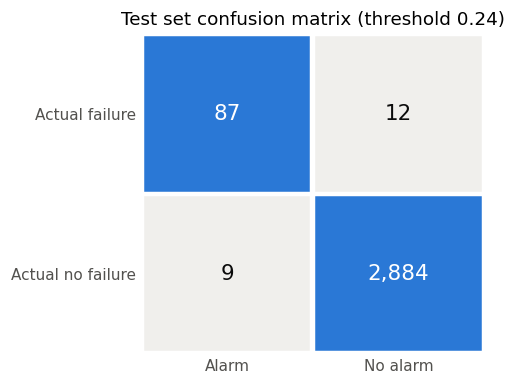

In [9]:
INK, MUTED, GRID, GRAY, BLUE, ORANGE = "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b3", "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.grid(False)
for i in range(2):
    for j in range(2):
        correct = i == j
        ax.add_patch(plt.Rectangle((j - 0.48, i - 0.48), 0.96, 0.96, color=BLUE if correct else "#f0efec"))
        ax.text(j, i, f"{confusion.iloc[i, j]:,}", ha="center", va="center", fontsize=14,
                color="white" if correct else INK)
ax.set_xticks([0, 1], confusion.columns)
ax.set_yticks([0, 1], confusion.index)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(1.5, -0.5)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
ax.set_title(f"Test set confusion matrix (threshold {threshold})")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_confusion_matrix.png")

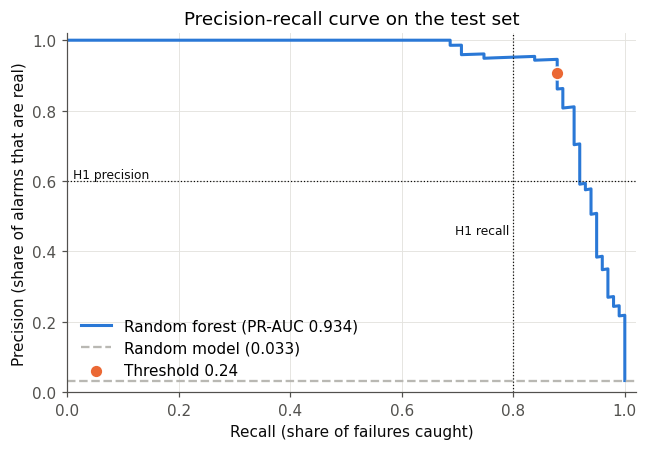

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.2))
precision, recall, _ = precision_recall_curve(y_test, probability)
ax.plot(recall, precision, color=BLUE, linewidth=2, label=f"Random forest (PR-AUC {point['PR-AUC']:.3f})")
ax.axhline(y_test.mean(), color=GRAY, linewidth=1.5, linestyle="--", label=f"Random model ({y_test.mean():.3f})")
ax.scatter(result["recall"], result["precision"], s=70, color=ORANGE, edgecolor="white", linewidth=1, zorder=3,
           label=f"Threshold {threshold}")
ax.axvline(H1_MIN_RECALL, color=INK, linewidth=0.8, linestyle=":")
ax.axhline(H1_MIN_PRECISION, color=INK, linewidth=0.8, linestyle=":")
ax.text(H1_MIN_RECALL, 0.45, "H1 recall ", color=INK, fontsize=8, ha="right")
ax.text(0.01, H1_MIN_PRECISION, "H1 precision", color=INK, fontsize=8, va="bottom")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall (share of failures caught)")
ax.set_ylabel("Precision (share of alarms that are real)")
ax.set_title("Precision-recall curve on the test set")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_precision_recall_test.png")

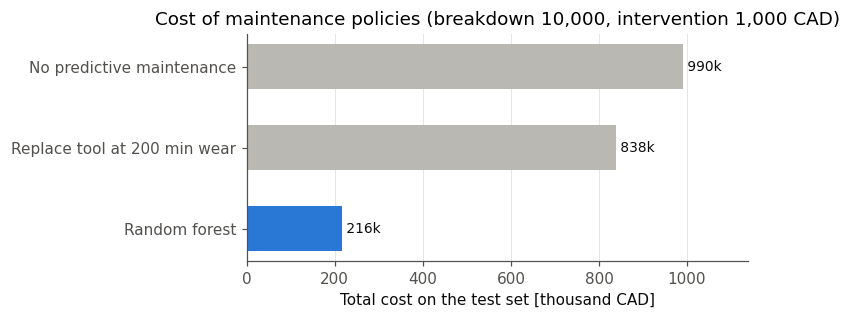

In [11]:
labels = list(policies.index)
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(labels[::-1], policies["cost"][::-1] / 1000, color=[BLUE, GRAY, GRAY], height=0.55)
for bar, cost in zip(bars, policies["cost"][::-1]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {cost / 1000:,.0f}k", va="center", color=INK, fontsize=9)
ax.set_xlim(0, policies["cost"].max() / 1000 * 1.15)
ax.set_xlabel(f"Total cost on the test set [thousand {CURRENCY}]")
ax.set_title(f"Cost of maintenance policies (breakdown {COST_FAILURE:,}, intervention {COST_INTERVENTION:,} {CURRENCY})")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_policy_costs.png")